In [1]:
import sys
sys.path.insert(0,"..")
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from model import MLP
import torch
import json
from utils import load_checkpoint

RUNS = Path("..") / "runs"
run_dir = sorted(RUNS.glob("*_mlp_seed42"))[-1]   # newest main run

print(run_dir)

with open(run_dir/"config.json") as f:
    run_config = json.load(f)

../runs/2026-11-03_00-56-29_mlp_seed42


In [2]:
def get_embeddings(epoch):
        """create model from historic saved config and load a checkpoint i.e some epoch"""
        model = MLP(run_config["p"],run_config["d_embed"],run_config["d_hidden"])
        model = load_checkpoint(model, run_dir / "checkpoints" / f"epoch_{epoch:06d}.pt")
        return model.deep_stack[0].weight.detach()

In [3]:
E = get_embeddings(20_000)
print(E.shape)

torch.Size([53, 128])


In [4]:
E_c = E - E.mean(dim=0) # centre the data
U,s,Vh = torch.linalg.svd(E_c,full_matrices=False)
coords = U*s
print(U.shape,s.shape,Vh.shape,coords.shape)

torch.Size([53, 53]) torch.Size([53]) torch.Size([53, 128]) torch.Size([53, 53])


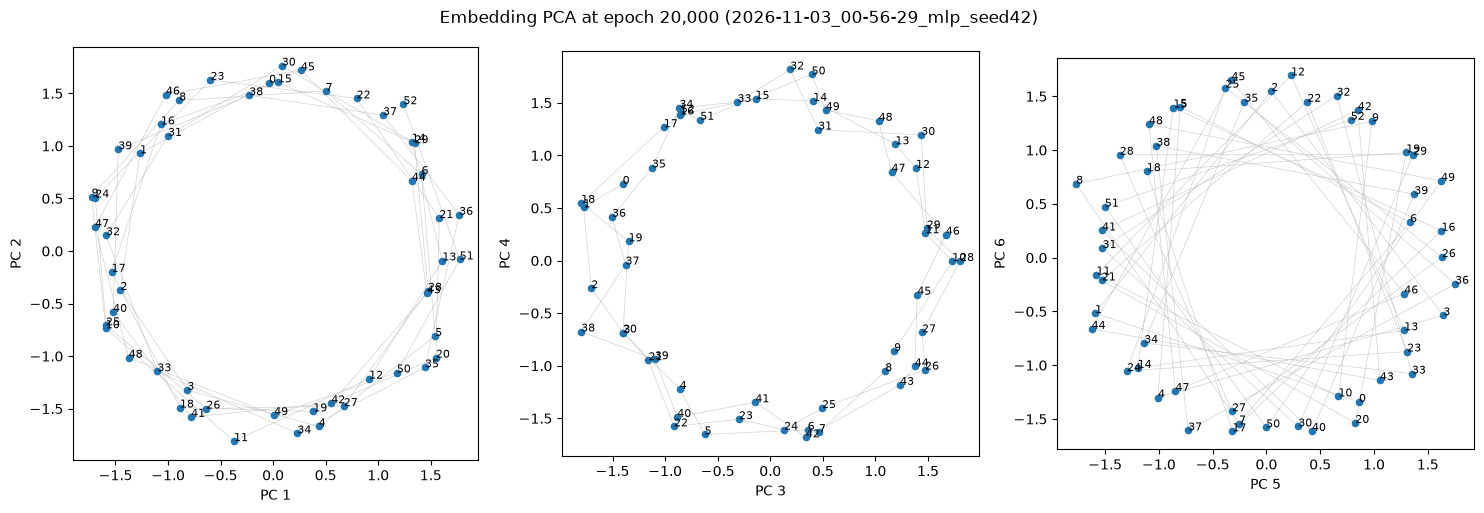

In [5]:
pairs = [(0, 1), (2, 3), (4, 5)]          # PC1-2, PC3-4, PC5-6 (zero-based columns)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (i, j) in zip(axes, pairs):
    x, y = coords[:, i], coords[:, j]
    ax.plot(x, y, color="lightgray", linewidth=0.5, zorder=1)   # faint path 0 → 1 → 2 → ...
    ax.scatter(x, y, s=20, zorder=2)
    for n in range(len(x)):
        ax.text(x[n], y[n], str(n), fontsize=8)
    ax.set_aspect("equal")
    ax.set_xlabel(f"PC {i + 1}")
    ax.set_ylabel(f"PC {j + 1}")

fig.suptitle(f"Embedding PCA at epoch 20,000 ({run_dir.name})")
plt.tight_layout()
plt.savefig("figures/stage1_embedding_pca.png", dpi=200)
plt.show()

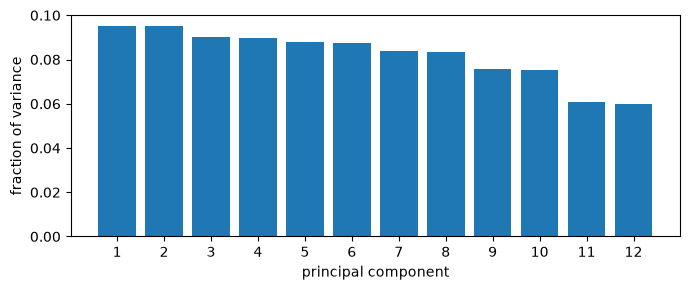

In [6]:
frac = (s**2 / (s**2).sum())[:12]
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(range(1, 13), frac)
ax.set_xlabel("principal component")
ax.set_ylabel("fraction of variance")
ax.set_xticks(range(1, 13))
plt.tight_layout()
plt.show()


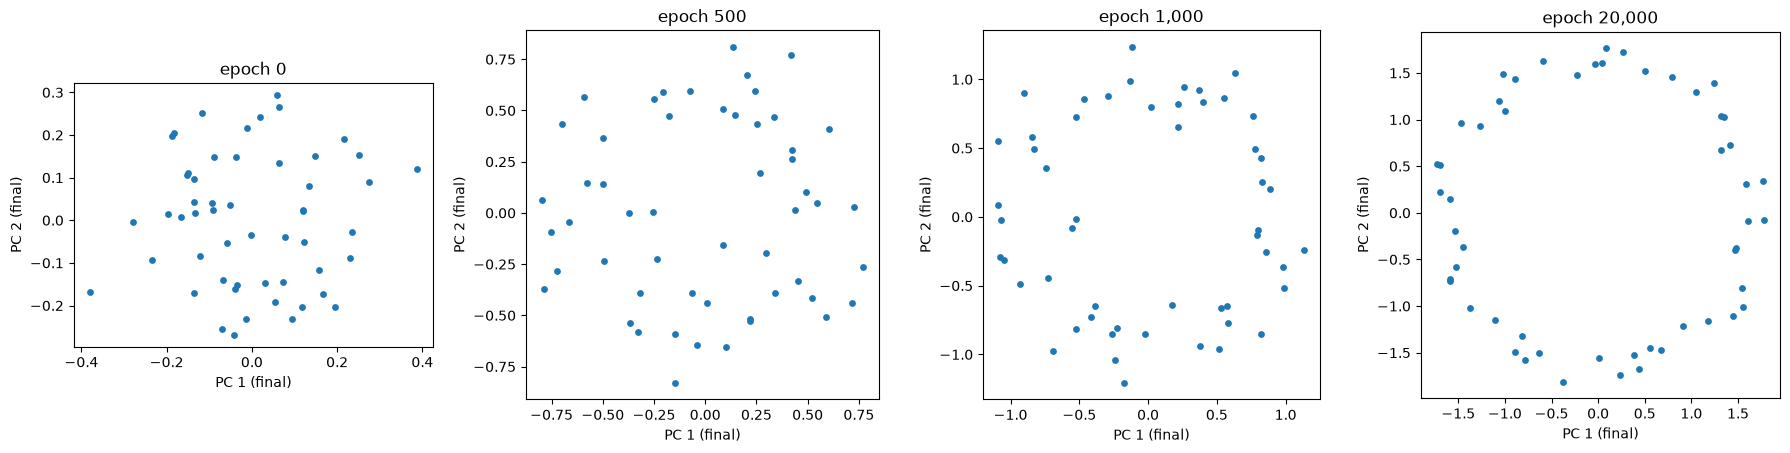

In [7]:
epochs = [0, 500, 1000, 20_000]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for ax, ep in zip(axes, epochs):
    E_ep = get_embeddings(ep)
    proj = (E_ep - E_ep.mean(dim=0)) @ Vh[:2].T       # onto the FINAL model's PC1 and PC2
    ax.scatter(proj[:, 0], proj[:, 1], s=15)
    ax.set_aspect("equal")
    ax.set_title(f"epoch {ep:,}")
    ax.set_xlabel("PC 1 (final)")
    ax.set_ylabel("PC 2 (final)")

plt.tight_layout()
plt.savefig("figures/stage1_embedding_evolution.png", dpi=200)
plt.show()